In [1]:
import json, numpy as np, pandas as pd
from scipy.special import softmax
from complaint.calibration import corrected_logits, nll, fit_temperature, ece, reliability_table
from complaint.evaluation import prior_log_ratio

DATA = "/mnt/c/Users/leomu/Downloads/complaint-triage"
TAU = 0.75

preds = pd.read_parquet("../data/preds_test.parquet")
names = sorted(preds["label"].unique())
label2id = {n: i for i,n in enumerate(names)}
y_test = preds['label'].map(label2id).to_numpy()
L_test = np.load("../data/logits_test.npy")

train_y = pd.read_parquet(f"{DATA}/train.parquet", columns=["label"])["label"].map(label2id).to_numpy()
val_y_all = pd.read_parquet(f"{DATA}/val.parquet", columns=["label"])["label"].map(label2id).to_numpy()
log_ratio = prior_log_ratio(train_y, val_y_all, len(names))

In [8]:
L_val, y_val = np.load("../data/logits_val.npy"), np.load("../data/labels_val.npy")
T = fit_temperature(L_val, y_val, log_ratio, tau=TAU)
print(f"T = {T:.3f}")  


T = 1.128


since T > 1, the model was overconfident.

In [3]:
from sklearn.metrics import f1_score

versions = {
    "raw":         L_test,
    "prior-adj":   corrected_logits(L_test, log_ratio, tau=TAU),
    "prior+temp":  corrected_logits(L_test, log_ratio, temperature=T, tau=TAU),
}
rows = []
for name, z in versions.items():
    p = softmax(z, axis=1)
    rows.append({"version": name, "ECE": ece(p, y_test), "NLL": nll(z, y_test),
                 "macro-F1": f1_score(y_test, p.argmax(1), average="macro")})
pd.DataFrame(rows).round(4)

,version,ECE,NLL,macro-F1
0,raw,0.0356,0.5217,0.7285
1,prior-adj,0.0394,0.4606,0.7534
2,prior+temp,0.0185,0.4508,0.7534


In [6]:
adj  = show_reliability(p_adj, y_test).set_index("bin")
temp = show_reliability(p_temp, y_test).set_index("bin")
pd.concat({"prior-adj": adj, "+ temperature": temp}, axis=1)


prior-adj                                   + temperature             \
                n confidence accuracy    gap  share             n confidence   
bin                                                                            
0.1-0.2         1      0.187    0.000 -0.187  0.000             2      0.189   
0.2-0.3        17      0.243    0.235 -0.008  0.001            27      0.243   
0.3-0.3        47      0.304    0.298 -0.007  0.002            61      0.305   
0.3-0.4       114      0.371    0.333 -0.038  0.006           152      0.369   
0.4-0.5       201      0.438    0.388 -0.050  0.010           257      0.435   
0.5-0.5       534      0.505    0.478 -0.028  0.027           665      0.503   
0.5-0.6       675      0.567    0.502 -0.065  0.034           793      0.566   
0.6-0.7       723      0.632    0.542 -0.090  0.036           830      0.634   
0.7-0.7       847      0.701    0.630 -0.071  0.042           954      0.700   
0.7-0.8      1004      0.769    0.665 -0.104  0.050          1277      0.768   
0.8-0.9      1421      0.835    0.769 -0.066  0.071          1698      0.835   
0.9-0.9      2301      0.902    0.854 -0.049  0.115          2633      0.904   
0.9-1.0     12115      0.983    0.960 -0.023  0.606         10651      0.978   

                                
        accuracy    gap  share  
bin                             
0.1-0.2    0.000 -0.189  0.000  
0.2-0.3    0.185 -0.057  0.001  
0.3-0.3    0.361  0.055  0.003  
0.3-0.4    0.349 -0.020  0.008  
0.4-0.5    0.393 -0.042  0.013  
0.5-0.5    0.498 -0.005  0.033  
0.5-0.6    0.525 -0.042  0.040  
0.6-0.7    0.590 -0.043  0.042  
0.7-0.7    0.658 -0.042  0.048  
0.7-0.8    0.725 -0.043  0.064  
0.8-0.9    0.824 -0.010  0.085  
0.9-0.9    0.885 -0.020  0.132  
0.9-1.0    0.967 -0.011  0.533

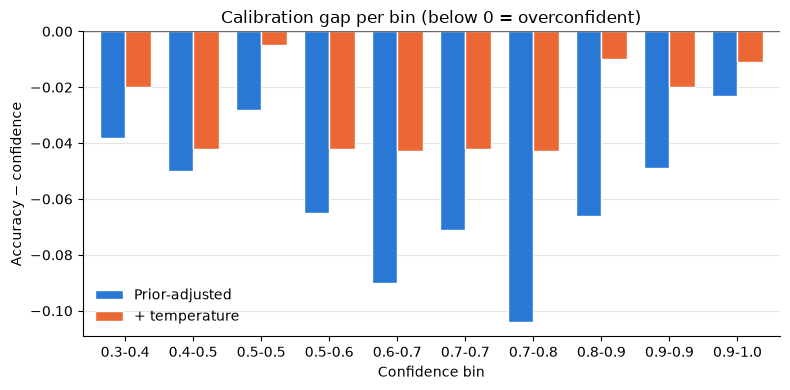

In [7]:
import matplotlib.pyplot as plt

cmp = pd.concat({"Prior-adjusted": adj["gap"], "+ temperature": temp["gap"]}, axis=1)
cmp = cmp[adj["n"].reindex(cmp.index).fillna(0) >= 100]   # drop noisy bins (< 100 complaints)

ax = cmp.plot.bar(figsize=(8, 4), width=0.75, color=["#2a78d6", "#eb6834"],
                  edgecolor="white", linewidth=1)
ax.axhline(0, color="#6b6a63", lw=1)
ax.set(xlabel="Confidence bin", ylabel="Accuracy − confidence",
       title="Calibration gap per bin (below 0 = overconfident)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3de"); ax.set_axisbelow(True)
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
